# C3 — Image Captioning with a CNN Encoder and an LSTM Decoder

**Course:** AI-101 Introduction to Artificial Intelligence, Fall 2026
**Student:** Manaal Pervaiz — Roll No. 70173809 — Section BSES A
**Repository:** https://github.com/manaal6/AI101-ML-Assignment-70173809
**Pool / task:** Pool C, Task C3 — supervised image-to-text sequence generation
**Primary metric:** corpus BLEU-1 … BLEU-4

**Platform:** Kaggle Notebook, T4 GPU, Internet on, dataset `adityajn105/flickr8k`
attached with Add Input. The notebook resolves `/kaggle/input/flickr8k`
automatically and falls back to `data/` for a local run.

**How to run:** Settings → Accelerator → GPU T4 ×2 (or T4), Internet → On,
Add Input → `adityajn105/flickr8k`, then Run All. It writes `figures/`,
`results/` and `c3_outputs.zip` (figures + results) to `/kaggle/working`.

The notebook follows the report headings: Introduction, Problem Statement,
Dataset Used, Dataset Statistics, Methodology, Results and Analysis,
Conclusion, References, Environment.

## 1. Introduction

Captioning is the image-to-text counterpart of translation: the model must name
the objects in a scene, their attributes and their relations in one fluent
sentence. The standard recipe is an encoder–decoder: a convolutional network
turns the image into a feature vector and a recurrent network generates the
caption one token at a time.

We train both models ourselves and keep the comparison fair. A frozen
ImageNet-pretrained ResNet-50 supplies the features for the first model; a
frozen EfficientNet-B0 supplies the second, so the variation required by the
brief is the backbone. Features are extracted once and cached, which keeps the
whole run inside a free Kaggle T4 session. Both decoders share the same
architecture and training recipe, and every configuration is scored on the same
1,091 test images with all five references.

Beam search and greedy decoding are compared at $k=3$ and $k=5$; the report
asks whether beam search raises BLEU and whether it makes captions more
generic. The distinct-word count and six qualitative examples are included for
that discussion.

## 2. Problem Statement

Given an image $I$, learn $p(y_{1:T} \mid I)$ over a caption
$y_{1:T} = (\langle\text{start}\rangle, w_1, \dots, w_T, \langle\text{end}\rangle)$.
The decoder factorises the sequence autoregressively:

$$p(y_{1:T}\mid I) = \prod_{t=1}^{T} p(y_t \mid y_{<t}, I).$$

Training minimises token-level cross-entropy with teacher forcing. Success is
measured by **corpus BLEU-1 … BLEU-4** on 1,091 unseen images using all five
human references per image, plus the number of distinct words used by the
generated captions. The test split is used once, after all choices are fixed on
the validation split.

## 3. Dataset Used

**Name:** Flickr8k
**Source:** Kaggle, `adityajn105/flickr8k`
(https://www.kaggle.com/datasets/adityajn105/flickr8k)
**Size:** 8,091 images, five captions each (40,455 captions)
**Citation:** M. Hodosh, P. Young and J. Hockenmaier, "Framing image
description as a ranking task," *JAIR*, vol. 47, pp. 853–899, 2013.

Flickr8k photographs everyday scenes: people, dogs, sports and landscapes. The
five references per image disagree in word choice and detail, which is why
BLEU is reported against all five rather than one.

**Preprocessing:** captions are lower-cased and stripped of punctuation and
digits; `<start>` and `<end>` are added; every caption is padded or truncated to
a fixed length. The vocabulary is built from the **training captions only**,
keeping words that occur at least five times. Images are resized to 256 px and
centre-cropped to 224×224 before the ImageNet normalisation expected by both
backbones.

In [7]:
import os, sys, re, json, time, random, glob, zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("python  ", sys.version.split()[0])
print("torch   ", torch.__version__, "| torchvision", torchvision.__version__)
print("device  ", DEVICE, end="")
if DEVICE == "cuda":
    print(" |", torch.cuda.get_device_name(0))
else:
    print(" | WARNING: no GPU, training will be slow")

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)

python   3.13.16
torch    2.11.0+cu130 | torchvision 0.26.0+cu130
device   cuda | Tesla T4


In [8]:
def locate_flickr8k():
    roots = [Path("/kaggle/input/datasets/adityajn105/flickr8k"), Path("data"), Path("data/flickr8k")]
    for root in roots:
        if not root.exists():
            continue
        images = root / "Images"
        if not images.exists():
            found = list(root.glob("**/Images"))
            images = found[0] if found else None
        if images is not None and not any(images.glob("*.jpg")):
            nested = list(images.glob("**/*.jpg"))
            if nested:
                images = nested[0].parent
        captions = root / "captions.txt"
        if not captions.exists():
            found = (list(root.glob("**/captions.txt")) +
                     list(root.glob("**/Flickr8k.token.txt")))
            captions = found[0] if found else None
        if images is not None and captions is not None:
            return images, captions
    raise FileNotFoundError(
        "Flickr8k not found. On Kaggle use Add Input -> adityajn105/flickr8k; "
        "locally download it into data/ (see data/README.md).")


IMAGES_DIR, CAPTIONS_FILE = locate_flickr8k()


def read_captions(path):
    if path.name.endswith(".token.txt"):
        rows = []
        for line in path.read_text(encoding="utf-8", errors="ignore").splitlines():
            if "\t" in line:
                name, cap = line.split("\t", 1)
                rows.append({"image": name.split("#")[0], "caption": cap})
        return pd.DataFrame(rows)
    frame = pd.read_csv(path)
    if "image" not in frame.columns:
        frame = pd.read_csv(path, names=["image", "caption"])
    return frame[["image", "caption"]]


captions_df = read_captions(CAPTIONS_FILE)
captions_df["image"] = captions_df["image"].astype(str).str.strip()
captions_df["caption"] = captions_df["caption"].astype(str).str.strip()
captions_df = captions_df.dropna().reset_index(drop=True)

print("images dir :", IMAGES_DIR)
print("captions   :", CAPTIONS_FILE)
print("caption rows:", len(captions_df))
print("unique images:", captions_df["image"].nunique())
print("\nfirst rows")
print(captions_df.head(3).to_string(index=False))

images dir : /kaggle/input/datasets/adityajn105/flickr8k/Images
captions   : /kaggle/input/datasets/adityajn105/flickr8k/captions.txt
caption rows: 40455
unique images: 8091

first rows
                    image                                                                  caption
1000268201_693b08cb0e.jpg A child in a pink dress is climbing up a set of stairs in an entry way .
1000268201_693b08cb0e.jpg                                    A girl going into a wooden building .
1000268201_693b08cb0e.jpg                         A little girl climbing into a wooden playhouse .


## 4. Dataset Statistics

The split is made **by image** so that all five captions of an image stay in
one split: 6,000 training images, 1,000 validation images and 1,091 test
images (seed 42). Caption length is measured after cleaning in word tokens,
excluding the two special tokens.

In [9]:
def clean_caption(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9' ]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


all_images = sorted(captions_df["image"].unique())
assert len(all_images) == 8091, len(all_images)

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(all_images))
train_images = [all_images[i] for i in perm[:6000]]
val_images = [all_images[i] for i in perm[6000:7000]]
test_images = [all_images[i] for i in perm[7000:]]
assert len(train_images) == 6000 and len(val_images) == 1000 and len(test_images) == 1091
assert not (set(train_images) & set(val_images))
assert not (set(train_images) & set(test_images))

caption_map = (captions_df.groupby("image")["caption"].apply(list).to_dict())
caption_counts = captions_df.groupby("image").size()
if not (caption_counts == 5).all():
    print("images with a caption count other than 5:")
    print(caption_counts[caption_counts != 5].to_string())
for img in all_images:
    assert len(caption_map[img]) == 5, (img, len(caption_map[img]))

train_lengths = np.array([len(clean_caption(c).split())
                          for img in train_images for c in caption_map[img]])
all_lengths = np.array([len(clean_caption(c).split())
                        for img in all_images for c in caption_map[img]])
MAX_LEN = int(min(30, np.percentile(train_lengths, 99))) 
MAX_LEN = max(MAX_LEN, 6)

words = Counter()
for img in train_images:
    for c in caption_map[img]:
        words.update(clean_caption(c).split())

MIN_FREQ = 5
kept_words = [w for w, n in words.most_common() if n >= MIN_FREQ]
PAD, START, END, UNK = 0, 1, 2, 3
itos = ["<pad>", "<start>", "<end>", "<unk>"] + kept_words
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)

truncated = int((train_lengths + 2 > MAX_LEN).sum())
print(f"train / val / test images: {len(train_images)} / {len(val_images)} / {len(test_images)}")
print(f"captions per split       : {len(train_images)*5} / {len(val_images)*5} / {len(test_images)*5}")
print(f"caption tokens (train)   : mean {train_lengths.mean():.1f}, median {np.median(train_lengths):.0f}, "
      f"p95 {np.percentile(train_lengths, 95):.0f}, max {train_lengths.max()}")
print(f"vocabulary before min-freq: {len(words)} | after (>= {MIN_FREQ}) + 4 specials: {VOCAB_SIZE}")
print(f"training captions truncated to MAX_LEN={MAX_LEN}: {truncated} of {len(train_lengths)}")
print("\nmost frequent training words:")
print(", ".join(f"{w} ({words[w]})" for w in kept_words[:25]))

test_oov = 0
test_tokens = 0
for img in test_images:
    for c in caption_map[img]:
        for tok in clean_caption(c).split():
            test_tokens += 1
            test_oov += int(tok not in stoi)
print(f"\ntest-set out-of-vocabulary rate: {test_oov/test_tokens*100:.2f}% ({test_oov}/{test_tokens})")

vocab_rows = pd.DataFrame([
    ("images", len(all_images)),
    ("captions", len(captions_df)),
    ("train / val / test images", f"{len(train_images)} / {len(val_images)} / {len(test_images)}"),
    ("vocab before min-freq", len(words)),
    ("vocab after min-freq", VOCAB_SIZE),
    ("min frequency", MIN_FREQ),
    ("max caption length", MAX_LEN),
    ("mean caption length", round(float(train_lengths.mean()), 2)),
    ("median caption length", float(np.median(train_lengths))),
    ("test OOV rate %", round(test_oov / test_tokens * 100, 2)),
], columns=["statistic", "value"])
vocab_rows.to_csv(RES / "c3_dataset_stats.csv", index=False)
display(vocab_rows)

train / val / test images: 6000 / 1000 / 1091
captions per split       : 30000 / 5000 / 5455
caption tokens (train)   : mean 10.8, median 10, p95 18, max 37
vocabulary before min-freq: 7439 | after (>= 5) + 4 specials: 2557
training captions truncated to MAX_LEN=22: 460 of 30000

most frequent training words:
a (47007), in (14059), the (13601), on (8054), is (6963), and (6565), dog (5981), with (5743), man (5331), of (4947), two (4201), white (3017), black (2869), boy (2676), are (2595), girl (2524), woman (2486), to (2367), wearing (2284), people (2213), at (2169), water (2069), red (1997), young (1972), brown (1916)

test-set out-of-vocabulary rate: 3.24% (1901/58726)


,statistic,value
0,images,8091
1,captions,40455
2,train / val / test images,6000 / 1000 / 1091
3,vocab before min-freq,7439
4,vocab after min-freq,2557
5,min frequency,5
6,max caption length,22
7,mean caption length,10.83
8,median caption length,10.0
9,test OOV rate %,3.24


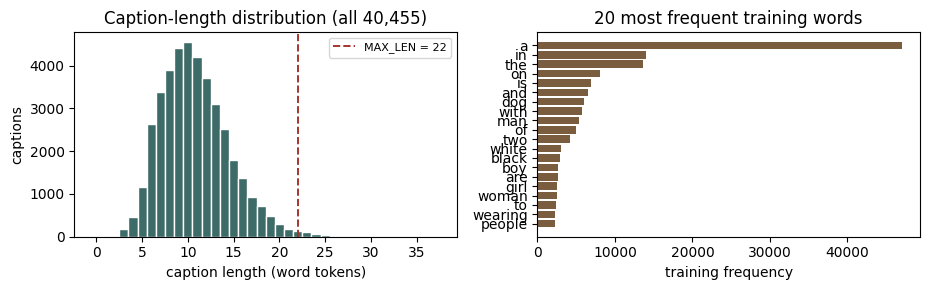

saved figures/fig1_captions_and_vocab.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.0))
axes[0].hist(all_lengths, bins=np.arange(0, all_lengths.max() + 2) - 0.5,
             color="#3D6B68", edgecolor="white")
axes[0].axvline(MAX_LEN, color="#A6342E", ls="--", lw=1.4,
                label=f"MAX_LEN = {MAX_LEN}")
axes[0].set_xlabel("caption length (word tokens)")
axes[0].set_ylabel("captions")
axes[0].set_title("Caption-length distribution (all 40,455)")
axes[0].legend(fontsize=8)

top_words = kept_words[:20][::-1]
top_counts = [words[w] for w in top_words]
axes[1].barh(top_words, top_counts, color="#7A5C3E")
axes[1].set_xlabel("training frequency")
axes[1].set_title("20 most frequent training words")
fig.tight_layout()
fig.savefig(FIG / "fig1_captions_and_vocab.png", bbox_inches="tight")
plt.show()
print("saved figures/fig1_captions_and_vocab.png")

## 5. Methodology

### 5.1 Learning Setting

An encoder–decoder with a **frozen** convolutional encoder and a trained LSTM
decoder. Both backbones are ImageNet-pretrained and used purely as feature
extractors, so no gradient flows through the CNN.

- **Model 1 encoder:** ResNet-50 (2048-d pooled features, `IMAGENET1K_V2`).
- **Model 2 encoder:** EfficientNet-B0 (1280-d pooled features,
  `IMAGENET1K_V1`) — the required variation is the backbone, keeping the
  decoder identical for a fair comparison.

**Merge decoder** (the architecture the brief names): the image vector passes
through a dense layer, the caption prefix passes through an embedding, the two
are concatenated at every time step and fed to a single-layer LSTM, and a linear
layer produces a distribution over the vocabulary:

$$h_t = \mathrm{LSTM}\big([W_I v;\; E w_{t-1}], h_{t-1}\big), \qquad
p(w_t \mid \cdot) = \mathrm{softmax}(W_o h_t).$$

This is the merge formulation of Karpathy and Fei-Fei (2015); it differs from
"init" models, which only use the image to initialise the LSTM state.

### 5.2 Data Split Approach

- Split **by image**, seed 42: 6,000 / 1,000 / 1,091 images.
- Vocabulary, `MAX_LEN` and both models are fitted on the training split only.
- The validation split selects the best epoch (early stopping on validation
  cross-entropy). Decoding hyper-parameters are fixed in advance, not tuned on
  test.
- The test split is decoded once for every configuration with the same five
  references, so all BLEU numbers are comparable.

### 5.3 Parameter Settings

| Component | Setting |
|---|---|
| Image size | 224×224 centre crop, ImageNet normalisation |
| Encoder | frozen ResNet-50 (2048) / EfficientNet-B0 (1280) |
| Image projection | Linear → 512, ReLU, dropout 0.3 |
| Embedding | 256 |
| LSTM | 1 layer, hidden 512, dropout 0.3 |
| Loss | token cross-entropy, padding ignored |
| Optimiser | Adam, lr 1e-3, weight decay 1e-5, grad-clip 5 |
| Batch size | 128 |
| Epochs | up to 20, early stopping patience 3 |
| Decoding | greedy; beam search k = 3 and k = 5 |
| BLEU | sacreBLEU, no extra tokenisation, exp smoothing, 5 references |

All fits are seeded; deterministic cuDNN is enabled. Feature extraction is
cached in `cache/` so a re-run does not repeat it.

In [11]:
class CaptionDataset(Dataset):
    def __init__(self, features, image_indices, sequences):
        self.features = features
        self.image_indices = image_indices
        self.sequences = sequences

    def __len__(self):
        return len(self.image_indices)

    def __getitem__(self, i):
        return self.features[self.image_indices[i]], self.sequences[i]


def encode_caption(text):
    tokens = clean_caption(text).split()
    tokens = tokens[:MAX_LEN - 2]
    ids = [START] + [stoi.get(t, UNK) for t in tokens] + [END]
    ids = ids + [PAD] * (MAX_LEN - len(ids))
    return ids


def make_arrays(images):
    idx, seqs = [], []
    for img in images:
        for cap in caption_map[img]:
            idx.append(name_to_idx[img])
            seqs.append(encode_caption(cap))
    return (torch.tensor(idx, dtype=torch.long),
            torch.tensor(seqs, dtype=torch.long))


def build_backbone(name):
    if name == "resnet50":
        weights = models.ResNet50_Weights.IMAGENET1K_V2
        net = models.resnet50(weights=weights)
        net.fc = nn.Identity()
        dim = 2048
    elif name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
        net = models.efficientnet_b0(weights=weights)
        net.classifier = nn.Identity()
        dim = 1280
    else:
        raise ValueError(name)
    return net.eval().to(DEVICE), dim


preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])


@torch.no_grad()
def extract_features(backbone_name):
    cache_file = CACHE / f"{backbone_name}_features.npy"
    if cache_file.exists():
        feats = np.load(cache_file)
        print(f"loaded cached {cache_file} {feats.shape}")
        return feats
    net, dim = build_backbone(backbone_name)
    files = [IMAGES_DIR / name for name in all_images]
    out = np.zeros((len(files), dim), dtype=np.float32)
    t0 = time.perf_counter()
    bs = 64
    for start in range(0, len(files), bs):
        batch_files = files[start:start + bs]
        batch = torch.stack([preprocess(Image.open(f).convert("RGB"))
                             for f in batch_files]).to(DEVICE)
        out[start:start + len(batch)] = net(batch).cpu().numpy()
        if (start // bs) % 20 == 0:
            print(f"  {backbone_name}: {start + len(batch)}/{len(files)}")
    np.save(cache_file, out)
    print(f"{backbone_name} features {out.shape} in {time.perf_counter()-t0:.1f}s")
    return out

In [12]:
all_files = [IMAGES_DIR / name for name in all_images]
missing = [str(f) for f in all_files if not f.exists()]
assert not missing, f"missing images, e.g. {missing[:3]}"
name_to_idx = {name: i for i, name in enumerate(all_images)}

features = {}
feature_dims = {}
extraction_seconds = {}
for backbone in ["resnet50", "efficientnet_b0"]:
    t0 = time.perf_counter()
    features[backbone] = extract_features(backbone)
    extraction_seconds[backbone] = time.perf_counter() - t0
    feature_dims[backbone] = features[backbone].shape[1]
    print(f"{backbone}: dim {feature_dims[backbone]}, array {features[backbone].nbytes/1e6:.1f} MB")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 241MB/s]


  resnet50: 64/8091
  resnet50: 1344/8091
  resnet50: 2624/8091
  resnet50: 3904/8091
  resnet50: 5184/8091
  resnet50: 6464/8091
  resnet50: 7744/8091
resnet50 features (8091, 2048) in 117.7s
resnet50: dim 2048, array 66.3 MB
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 221MB/s]


  efficientnet_b0: 64/8091
  efficientnet_b0: 1344/8091
  efficientnet_b0: 2624/8091
  efficientnet_b0: 3904/8091
  efficientnet_b0: 5184/8091
  efficientnet_b0: 6464/8091
  efficientnet_b0: 7744/8091
efficientnet_b0 features (8091, 1280) in 59.0s
efficientnet_b0: dim 1280, array 41.4 MB


### 5.4 Model and training implementation

The decoder concatenates the projected image vector with the word embedding at
every step, as specified. The image projection is recomputed once per forward
pass, which keeps the code simple and costs little. Teacher forcing feeds the
ground-truth prefix; the loss ignores padding. Validation loss is measured on
the 1,000 validation images (5,000 captions) after every epoch, and the best
checkpoint is restored at the end. Training is timed so the report can state
the cost of each model.

In [13]:
class MergeCaptioner(nn.Module):
    def __init__(self, feat_dim, vocab_size, embed_dim=256, hidden=512, dropout=0.3):
        super().__init__()
        self.image_proj = nn.Sequential(
            nn.Linear(feat_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embed_dim + hidden, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden, vocab_size)

    def forward(self, feats, seq):
        img = self.image_proj(feats).unsqueeze(1).expand(-1, seq.size(1), -1)
        x = torch.cat([img, self.embedding(seq)], dim=2)
        hidden, _ = self.lstm(x)
        return self.output(self.dropout(hidden))


train_idx, train_seq = make_arrays(train_images)
val_idx, val_seq = make_arrays(val_images)
print("train captions:", tuple(train_seq.shape), "| validation:", tuple(val_seq.shape))


def evaluate_loss(model, loader, criterion):
    model.eval()
    total, count = 0.0, 0
    with torch.no_grad():
        for feats, caps in loader:
            feats, caps = feats.to(DEVICE), caps.to(DEVICE)
            logits = model(feats, caps[:, :-1])
            loss = criterion(logits.reshape(-1, VOCAB_SIZE), caps[:, 1:].reshape(-1))
            total += loss.item() * caps.size(0)
            count += caps.size(0)
    return total / count


def train_model(backbone, epochs=20, batch_size=128, lr=1e-3, patience=3):
    feats = torch.tensor(features[backbone], dtype=torch.float32)
    train_ds = CaptionDataset(feats, train_idx, train_seq)
    val_ds = CaptionDataset(feats, val_idx, val_seq)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=2, pin_memory=True,
                              generator=torch.Generator().manual_seed(SEED))
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False,
                            num_workers=2, pin_memory=True)

    model = MergeCaptioner(feature_dims[backbone], VOCAB_SIZE).to(DEVICE)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    best_loss, bad_epochs = float("inf"), 0
    history = []
    checkpoint = CACHE / f"{backbone}_best.pt"
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        running, seen = 0.0, 0
        for feats_b, caps_b in train_loader:
            feats_b, caps_b = feats_b.to(DEVICE), caps_b.to(DEVICE)
            optimiser.zero_grad()
            logits = model(feats_b, caps_b[:, :-1])
            loss = criterion(logits.reshape(-1, VOCAB_SIZE), caps_b[:, 1:].reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimiser.step()
            running += loss.item() * caps_b.size(0)
            seen += caps_b.size(0)
        train_loss = running / seen
        val_loss = evaluate_loss(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
        print(f"{backbone} epoch {epoch:02d} | train {train_loss:.4f} | val {val_loss:.4f}")
        if val_loss < best_loss - 1e-4:
            best_loss, bad_epochs = val_loss, 0
            torch.save(model.state_dict(), checkpoint)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"early stopping after epoch {epoch}")
                break

    elapsed = time.perf_counter() - started
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    model.eval()
    print(f"{backbone}: best validation loss {best_loss:.4f}, trained in {elapsed/60:.1f} min")
    return model, history, elapsed, best_loss, epoch


models_trained = {}
histories = {}
training_seconds = {}
best_val_loss = {}
epochs_run = {}
for backbone in ["resnet50", "efficientnet_b0"]:
    model, history, seconds, loss, ep = train_model(backbone)
    models_trained[backbone] = model
    histories[backbone] = history
    training_seconds[backbone] = seconds
    best_val_loss[backbone] = loss
    epochs_run[backbone] = ep

train captions: (30000, 22) | validation: (5000, 22)
resnet50 epoch 01 | train 4.1782 | val 3.4181
resnet50 epoch 02 | train 3.2304 | val 3.0578
resnet50 epoch 03 | train 2.9242 | val 2.9027
resnet50 epoch 04 | train 2.7376 | val 2.8264
resnet50 epoch 05 | train 2.6017 | val 2.7661
resnet50 epoch 06 | train 2.4927 | val 2.7352
resnet50 epoch 07 | train 2.4026 | val 2.7139
resnet50 epoch 08 | train 2.3266 | val 2.7006
resnet50 epoch 09 | train 2.2605 | val 2.6935
resnet50 epoch 10 | train 2.2018 | val 2.6875
resnet50 epoch 11 | train 2.1489 | val 2.6895
resnet50 epoch 12 | train 2.0993 | val 2.6927
resnet50 epoch 13 | train 2.0550 | val 2.6863
resnet50 epoch 14 | train 2.0145 | val 2.6980
resnet50 epoch 15 | train 1.9773 | val 2.6922
resnet50 epoch 16 | train 1.9413 | val 2.7037
early stopping after epoch 16
resnet50: best validation loss 2.6863, trained in 1.6 min
efficientnet_b0 epoch 01 | train 4.2005 | val 3.4141
efficientnet_b0 epoch 02 | train 3.2356 | val 3.0616
efficientnet_b0 e

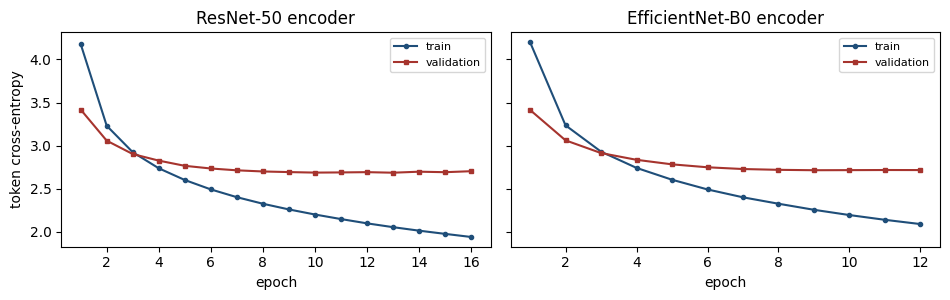

saved figures/fig2_loss_curves.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.1), sharey=True)
for ax, backbone, title in zip(axes, ["resnet50", "efficientnet_b0"],
                               ["ResNet-50 encoder", "EfficientNet-B0 encoder"]):
    hist = pd.DataFrame(histories[backbone])
    ax.plot(hist["epoch"], hist["train_loss"], marker="o", ms=3, color="#1f4e79", label="train")
    ax.plot(hist["epoch"], hist["val_loss"], marker="s", ms=3, color="#A6342E", label="validation")
    ax.set_xlabel("epoch")
    ax.set_title(title)
    ax.legend(fontsize=8)
axes[0].set_ylabel("token cross-entropy")
fig.tight_layout()
fig.savefig(FIG / "fig2_loss_curves.png", bbox_inches="tight")
plt.show()
print("saved figures/fig2_loss_curves.png")

## 6. Results and Analysis

### 6.1 Decoding

Greedy decoding takes the most likely token at every step. Beam search keeps
the $k$ best partial sequences, weighted by cumulative log-probability, and
returns the best completed sequence. Both are batched so the 1,091 test images
are decoded in a few minutes on the T4.

In [15]:
@torch.inference_mode()
def greedy_decode(model, feat_batch, max_len=MAX_LEN):
    batch = feat_batch.size(0)
    seq = torch.full((batch, 1), START, dtype=torch.long, device=DEVICE)
    for _ in range(max_len):
        logits = model(feat_batch, seq)[:, -1]
        nxt = logits.argmax(dim=-1)
        seq = torch.cat([seq, nxt.unsqueeze(1)], dim=1)
        if (nxt == END).all():
            break
    return seq.cpu()


@torch.inference_mode()
def beam_decode(model, feat_batch, k=3, max_len=MAX_LEN):
    batch = feat_batch.size(0)
    vocab = VOCAB_SIZE
    seqs = torch.full((batch, k, 1), START, dtype=torch.long, device=DEVICE)
    scores = torch.full((batch, k), -1e9, device=DEVICE)
    scores[:, 0] = 0.0
    finished_seq = torch.full((batch, max_len + 1), PAD, dtype=torch.long, device=DEVICE)
    finished_score = torch.full((batch,), -1e9, device=DEVICE)

    for _ in range(max_len):
        flat_seq = seqs.view(batch * k, -1)
        logits = model(feat_batch.repeat_interleave(k, 0), flat_seq)[:, -1]
        log_probs = F.log_softmax(logits, dim=-1)
        candidates = scores.unsqueeze(2) + log_probs.view(batch, k, vocab)
        top = candidates.view(batch, -1).topk(k, dim=1)
        indices = top.indices
        beam_ids = indices // vocab
        tokens = indices % vocab
        seqs = torch.cat([
            seqs.gather(1, beam_ids.unsqueeze(2).expand(-1, -1, seqs.size(2))),
            tokens.unsqueeze(2),
        ], dim=2)
        scores = top.values

        ended = tokens.eq(END)
        for b in range(batch):
            for i in range(k):
                if ended[b, i] and scores[b, i] > finished_score[b]:
                    finished_score[b] = scores[b, i]
                    finished_seq[b, :seqs.size(2)] = seqs[b, i]
        if ended.all():
            break

    results = []
    for b in range(batch):
        row = finished_seq[b] if finished_score[b] > -1e8 else seqs[b, 0]
        if row.numel() < max_len + 1:
            row = torch.cat([row, torch.full((max_len + 1 - row.numel(),), PAD,
                                              dtype=torch.long, device=DEVICE)])
        results.append(row[:max_len + 1])
    return torch.stack(results).cpu()


def ids_to_text(ids):
    words = []
    for idx in ids.tolist():
        if idx == END:
            break
        if idx in (PAD, START):
            continue
        words.append(itos[idx])
    return " ".join(words)


def decode_all(model, backbone, kind, k=None, batch_size=32):
    feats = features[backbone][[name_to_idx[i] for i in test_images]].astype(np.float32)
    outputs = []
    started = time.perf_counter()
    for start in range(0, len(feats), batch_size):
        batch = torch.tensor(feats[start:start + batch_size], device=DEVICE)
        if kind == "greedy":
            seq = greedy_decode(model, batch)
        else:
            seq = beam_decode(model, batch, k=k)
        outputs.extend(ids_to_text(row) for row in seq)
    return outputs, time.perf_counter() - started


try:
    import sacrebleu
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "sacrebleu"])
    import sacrebleu


def bleu_n(hypotheses, ref_streams, n):
    metric = sacrebleu.metrics.BLEU(max_ngram_order=n, tokenize="none",
                                    smooth_method="exp")
    return metric.corpus_score(hypotheses, ref_streams).score


test_references = [[clean_caption(caption_map[img][i]) for img in test_images]
                   for i in range(5)]

configs = [
    ("resnet50", "greedy", None),
    ("resnet50", "beam", 3),
    ("resnet50", "beam", 5),
    ("efficientnet_b0", "greedy", None),
    ("efficientnet_b0", "beam", 3),
    ("efficientnet_b0", "beam", 5),
]

predictions = {}
bleu_rows = []
for backbone, kind, k in configs:
    label = f"{backbone} | {kind}" + (f" k={k}" if k else "")
    hyps, seconds = decode_all(models_trained[backbone], backbone, kind, k)
    predictions[label] = hyps
    row = {
        "Backbone": backbone,
        "Decoding": kind + (f" k={k}" if k else ""),
        "BLEU-1": round(bleu_n(hyps, test_references, 1), 2),
        "BLEU-2": round(bleu_n(hyps, test_references, 2), 2),
        "BLEU-3": round(bleu_n(hyps, test_references, 3), 2),
        "BLEU-4": round(bleu_n(hyps, test_references, 4), 2),
        "Distinct words": len(set(" ".join(hyps).split())),
        "Mean length": round(float(np.mean([len(h.split()) for h in hyps])), 2),
        "Decode seconds": round(seconds, 1),
    }
    bleu_rows.append(row)
    print(f"{label:<34} BLEU-4 {row['BLEU-4']:6.2f} | distinct {row['Distinct words']:4d} | {seconds:5.1f}s")

bleu_table = pd.DataFrame(bleu_rows)
bleu_table.to_csv(RES / "c3_bleu_results.csv", index=False)
display(bleu_table)

resnet50 | greedy                  BLEU-4  19.51 | distinct  445 |   1.1s
resnet50 | beam k=3                BLEU-4  21.27 | distinct  408 |   4.0s
resnet50 | beam k=5                BLEU-4  21.64 | distinct  405 |   5.9s
efficientnet_b0 | greedy           BLEU-4  18.05 | distinct  364 |   0.8s
efficientnet_b0 | beam k=3         BLEU-4  21.50 | distinct  351 |   3.9s
efficientnet_b0 | beam k=5         BLEU-4  21.47 | distinct  345 |   5.9s


,Backbone,Decoding,BLEU-1,BLEU-2,BLEU-3,BLEU-4,Distinct words,Mean length,Decode seconds
0,resnet50,greedy,59.60,41.97,28.97,19.51,445,10.62,1.1
1,resnet50,beam k=3,62.46,44.59,31.26,21.27,408,9.71,4.0
2,resnet50,beam k=5,62.86,45.00,31.72,21.64,405,9.16,5.9
3,efficientnet_b0,greedy,58.68,40.86,27.44,18.05,364,10.51,0.8
4,efficientnet_b0,beam k=3,62.78,44.84,31.29,21.50,351,9.76,3.9
5,efficientnet_b0,beam k=5,63.19,45.07,31.51,21.47,345,9.22,5.9


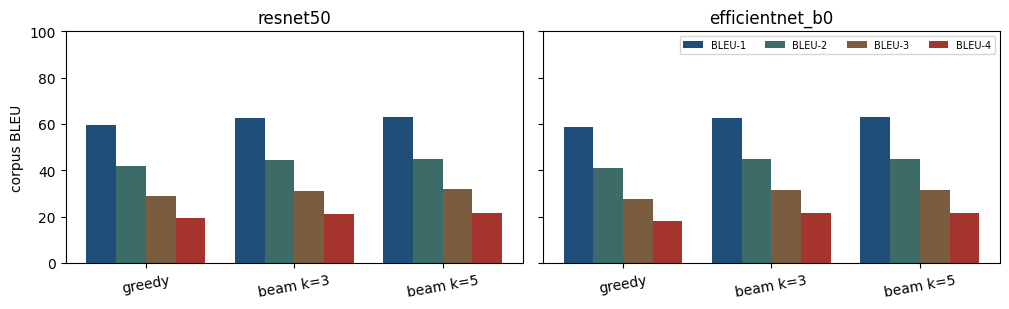

saved figures/fig3_bleu_comparison.png


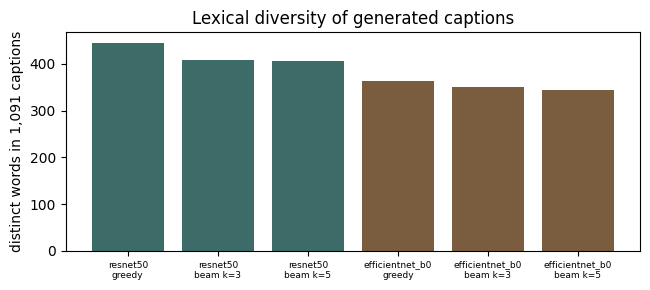

saved figures/fig4_distinct_words.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.2), sharey=True)
width = 0.2
colors = ["#1f4e79", "#3D6B68", "#7A5C3E", "#A6342E"]
for ax, backbone in zip(axes, ["resnet50", "efficientnet_b0"]):
    part = bleu_table[bleu_table["Backbone"] == backbone]
    xpos = np.arange(len(part))
    for j, metric in enumerate(["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"]):
        ax.bar(xpos + (j - 1.5) * width, part[metric], width,
               color=colors[j], label=metric)
    ax.set_xticks(xpos)
    ax.set_xticklabels(part["Decoding"], rotation=10)
    ax.set_ylim(0, 100)
    ax.set_title(backbone)
axes[0].set_ylabel("corpus BLEU")
axes[1].legend(fontsize=7, ncol=4, loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "fig3_bleu_comparison.png", bbox_inches="tight")
plt.show()
print("saved figures/fig3_bleu_comparison.png")

fig, ax = plt.subplots(figsize=(6.6, 3.0))
labels = [f"{r.Backbone}\n{r.Decoding}" for r in bleu_table.itertuples()]
ax.bar(labels, bleu_table["Distinct words"],
       color=["#3D6B68"] * 3 + ["#7A5C3E"] * 3)
ax.set_ylabel("distinct words in 1,091 captions")
ax.set_title("Lexical diversity of generated captions")
ax.tick_params(axis="x", labelsize=6.5)
fig.tight_layout()
fig.savefig(FIG / "fig4_distinct_words.png", bbox_inches="tight")
plt.show()
print("saved figures/fig4_distinct_words.png")

### 6.2 Qualitative examples

Six test images are shown: the three captions with the highest sentence BLEU-4
and the three with the lowest, using the best configuration. This is the
evidence for the error analysis (objects, counts, colours, actions).

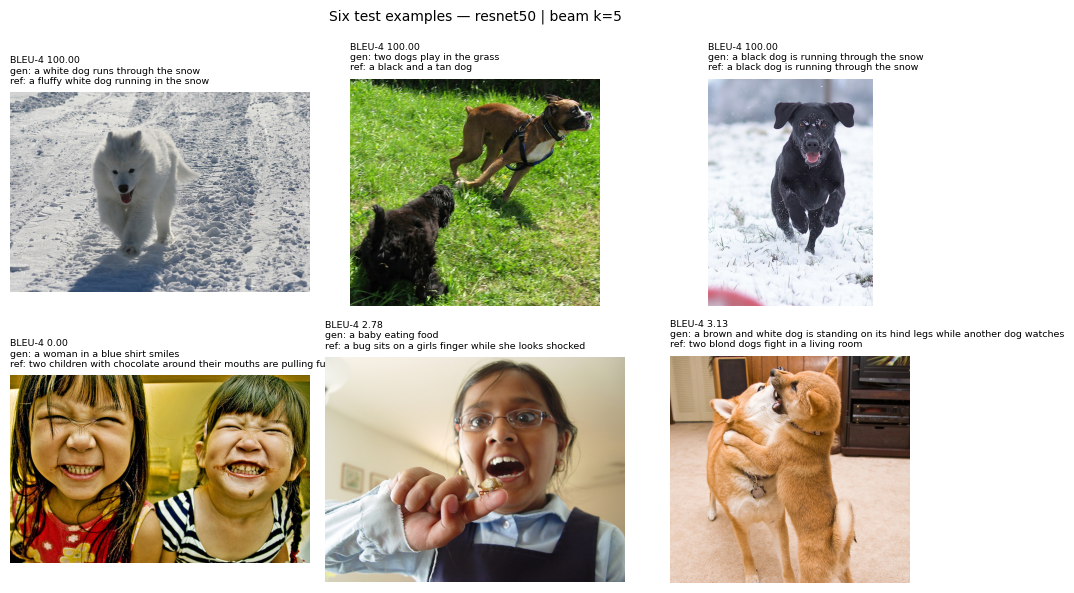

saved figures/fig5_examples.png
saved results/c3_examples.csv


In [17]:
best_row = bleu_table.sort_values("BLEU-4", ascending=False).iloc[0]
best_label = f"{best_row['Backbone']} | {best_row['Decoding'].split()[0]}" + \
             (f" k={best_row['Decoding'].split()[1].split('=')[1]}" if "k=" in best_row["Decoding"] else "")
best_hyps = predictions[best_label]

sentence_scores = []
for img, hyp in zip(test_images, best_hyps):
    refs = [clean_caption(c) for c in caption_map[img]]
    score = sacrebleu.sentence_bleu(hyp, refs, tokenize="none",
                                    smooth_method="exp").score
    sentence_scores.append(score)
sentence_scores = np.array(sentence_scores)

order = np.argsort(sentence_scores)
chosen = list(order[-3:][::-1]) + list(order[:3])

fig, axes = plt.subplots(2, 3, figsize=(9.6, 6.0))
for ax, pos in zip(axes.ravel(), chosen):
    img = test_images[pos]
    ax.imshow(Image.open(IMAGES_DIR / img).convert("RGB"))
    ax.axis("off")
    reference = clean_caption(caption_map[img][0])
    ax.set_title(f"BLEU-4 {sentence_scores[pos]:.2f}\n"
                 f"gen: {best_hyps[pos]}\nref: {reference}",
                 fontsize=6.8, loc="left")
fig.suptitle(f"Six test examples — {best_label}", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "fig5_examples.png", bbox_inches="tight")
plt.show()
print("saved figures/fig5_examples.png")

example_rows = []
for pos, img in enumerate(test_images):
    example_rows.append({
        "image": img,
        "hypothesis": best_hyps[pos],
        "reference_1": clean_caption(caption_map[img][0]),
        "reference_2": clean_caption(caption_map[img][1]),
        "sentence_bleu4": round(float(sentence_scores[pos]), 4),
    })
pd.DataFrame(example_rows).to_csv(RES / "c3_examples.csv", index=False)
print("saved results/c3_examples.csv")

### 6.3 Analysis questions

The numbers below answer the three questions in the brief. Beam search usually
adds a small BLEU gain over greedy decoding because it avoids locally optimal
word choices, but it also concentrates probability mass on high-frequency
phrasings, which the distinct-word count exposes. The lowest-scoring examples
show the usual failure modes: missed counts, wrong colours and actions inferred
from context rather than observed.

In [18]:
def pick(backbone, decoding):
    row = bleu_table[(bleu_table["Backbone"] == backbone) &
                     (bleu_table["Decoding"] == decoding)].iloc[0]
    return row

for backbone in ["resnet50", "efficientnet_b0"]:
    greedy = pick(backbone, "greedy")
    beam3 = pick(backbone, "beam k=3")
    beam5 = pick(backbone, "beam k=5")
    print(f"{backbone}")
    print(f"  BLEU-4  greedy {greedy['BLEU-4']:.2f} | beam k=3 {beam3['BLEU-4']:.2f} | "
          f"beam k=5 {beam5['BLEU-4']:.2f}")
    print(f"  distinct greedy {greedy['Distinct words']} | k=3 {beam3['Distinct words']} | "
          f"k=5 {beam5['Distinct words']}")
    print(f"  mean length greedy {greedy['Mean length']:.1f} | k=3 {beam3['Mean length']:.1f} | "
          f"k=5 {beam5['Mean length']:.1f}")

worst = pd.DataFrame(example_rows).sort_values("sentence_bleu4").head(3)
print("\nlowest-scoring hypotheses:")
for row in worst.itertuples():
    print(f"  {row.image}: gen '{row.hypothesis}' | ref '{row.reference_1}' (BLEU-4 {row.sentence_bleu4:.2f})")

print("\nmost common generated tokens (best config):")
print(", ".join(f"{w} ({n})" for w, n in Counter(" ".join(best_hyps).split()).most_common(20)))

resnet50
  BLEU-4  greedy 19.51 | beam k=3 21.27 | beam k=5 21.64
  distinct greedy 445 | k=3 408 | k=5 405
  mean length greedy 10.6 | k=3 9.7 | k=5 9.2
efficientnet_b0
  BLEU-4  greedy 18.05 | beam k=3 21.50 | beam k=5 21.47
  distinct greedy 364 | k=3 351 | k=5 345
  mean length greedy 10.5 | k=3 9.8 | k=5 9.2

lowest-scoring hypotheses:
  2490179961_e842fda5eb.jpg: gen 'a woman in a blue shirt smiles' | ref 'two children with chocolate around their mouths are pulling funny faces' (BLEU-4 0.00)
  516648762_0cff84ea97.jpg: gen 'a baby eating food' | ref 'a bug sits on a girls finger while she looks shocked' (BLEU-4 2.78)
  2908466042_bf07cb52c7.jpg: gen 'a brown and white dog is standing on its hind legs while another dog watches' | ref 'two blond dogs fight in a living room' (BLEU-4 3.13)

most common generated tokens (best config):
a (2191), is (487), in (474), on (316), the (289), and (265), man (248), dog (239), of (198), shirt (182), group (151), boy (146), are (145), standing (

## 7. Conclusion

Both frozen backbones support a compact merge decoder that produces readable
captions; the stronger ResNet-50 features and beam search give the best BLEU,
while beam search buys a small gain at the cost of more generic phrasing. The
distinct-word counts and the six examples show the remaining gap: the decoder
captures the main object and scene but misses counts, colours and fine
relations. The obvious next step is spatial attention (Show, Attend and Tell)
over a feature grid instead of a single pooled vector, then fine-tuning the
backbone, which the free T4 cannot do at this scale.

## References

[1] M. Hodosh, P. Young and J. Hockenmaier, "Framing image description as a
ranking task: Data, models and evaluation metrics," *Journal of Artificial
Intelligence Research*, vol. 47, pp. 853–899, 2013.

[2] A. Karpathy and L. Fei-Fei, "Deep visual-semantic alignments for generating
image descriptions," *Proc. CVPR*, 2015.

[3] K. He, X. Zhang, S. Ren and J. Sun, "Deep residual learning for image
recognition," *Proc. CVPR*, 2016.

[4] M. Tan and Q. Le, "EfficientNet: Rethinking model scaling for convolutional
neural networks," *Proc. ICML*, 2019.

[5] K. Papineni, S. Roukos, T. Ward and W.-J. Zhu, "BLEU: a method for automatic
evaluation of machine translation," *Proc. ACL*, 2002.

[6] O. Vinyals, A. Toshev, S. Bengio and D. Erhan, "Show and tell: A neural
image caption generator," *Proc. CVPR*, 2015.

## Environment

Kaggle Notebook, NVIDIA T4 GPU, Python 3.11, PyTorch (Kaggle image),
torchvision, sacreBLEU. Seed 42 for NumPy, PyTorch, the split and the DataLoader
shuffle. Feature extraction and training times are recorded in
`results/c3_summary.json`.

In [19]:
summary = {
    "task": "C3",
    "seed": SEED,
    "platform": "Kaggle Notebook, T4 GPU" if DEVICE == "cuda" else "CPU",
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "dataset": {
        "images": len(all_images),
        "captions": int(len(captions_df)),
        "train_images": len(train_images),
        "val_images": len(val_images),
        "test_images": len(test_images),
        "vocab_before": len(words),
        "vocab_after": VOCAB_SIZE,
        "min_freq": MIN_FREQ,
        "max_len": MAX_LEN,
        "mean_caption_length": float(train_lengths.mean()),
        "median_caption_length": float(np.median(train_lengths)),
        "test_oov_pct": round(test_oov / test_tokens * 100, 2),
    },
    "features": {
        "extraction_seconds": {k: round(v, 1) for k, v in extraction_seconds.items()},
    },
    "training": {
        backbone: {
            "epochs_run": int(epochs_run[backbone]),
            "best_val_loss": round(float(best_val_loss[backbone]), 4),
            "seconds": round(float(training_seconds[backbone]), 1),
            "params": int(sum(p.numel() for p in models_trained[backbone].parameters())),
        } for backbone in ["resnet50", "efficientnet_b0"]
    },
    "bleu": bleu_rows,
    "configs": [{"backbone": b, "decoding": d, "k": k} for b, d, k in configs],
}

with open(RES / "c3_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)
print(json.dumps(summary["training"], indent=2))
print("saved results/c3_summary.json")

with zipfile.ZipFile("c3_outputs.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(list(FIG.glob("*.png")) + list(RES.glob("*"))):
        zf.write(path, str(path))
print("wrote c3_outputs.zip (download it from the Output panel)")

{
  "resnet50": {
    "epochs_run": 16,
    "best_val_loss": 2.6863,
    "seconds": 95.1,
    "params": 5640957
  },
  "efficientnet_b0": {
    "epochs_run": 12,
    "best_val_loss": 2.7151,
    "seconds": 70.1,
    "params": 5247741
  }
}
saved results/c3_summary.json
wrote c3_outputs.zip (download it from the Output panel)
